# 01 · Return Distributions & Normality Analysis

**Project:** NSE Risk-Return Profiler & Portfolio Optimizer
**Question answered here:** Are NSE stock returns normally distributed, and what does that imply for risk measurement?

**Universe:** 30 NSE large-cap stocks across 9 sectors, plus NIFTY 50 as benchmark
**Data:** Daily split- and dividend-adjusted closes, Jan 2018 to Oct 2026 (Yahoo Finance)

**Approach**
1. Convert prices to daily log returns
2. Summarize annualized return, volatility, skewness, and excess kurtosis per stock
3. Test normality formally (Jarque-Bera) and visually (histogram on log scale, Q-Q plots)
4. Compare tail behavior across stocks and sectors

In [8]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config
from src.metrics import log_returns, distribution_summary

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [14]:
prices = pd.read_csv(config.PROCESSED_DIR / "prices_stocks.csv", index_col=0, parse_dates=True)
bench = pd.read_csv(config.PROCESSED_DIR / "prices_benchmark.csv", index_col=0, parse_dates=True)

returns = log_returns(prices)
bench_ret = log_returns(bench)

returns.to_csv(config.PROCESSED_DIR / "returns_stocks.csv")
bench_ret.to_csv(config.PROCESSED_DIR / "returns_benchmark.csv")
print(returns.shape)

(2179, 30)


In [15]:
summary = distribution_summary(returns)
summary["sector"] = summary.index.map(config.SECTOR_MAP)
summary.to_csv(config.PROCESSED_DIR / "distribution_summary.csv")

print("Stocks rejecting normality:", summary["reject_normality"].sum(), "of", len(summary))
summary.sort_values("excess_kurtosis", ascending=False).round(3).head(10)

Stocks rejecting normality: 30 of 30


,ann_log_return,ann_volatility,skewness,excess_kurtosis,worst_day,best_day,jb_stat,jb_pvalue,reject_normality,sector
AXISBANK.NS,0.091,0.329,-1.552,34.471,-0.327,0.178,108246.874,0.0,True,Banking & Financials
BAJFINANCE.NS,0.200,0.358,-0.850,12.435,-0.264,0.104,14231.184,0.0,True,Banking & Financials
ICICIBANK.NS,0.180,0.291,-0.443,12.018,-0.197,0.129,13118.908,0.0,True,Banking & Financials
ONGC.NS,0.070,0.343,-0.492,11.498,-0.184,0.170,12029.328,0.0,True,Energy & Utilities
MARUTI.NS,0.030,0.282,-0.154,11.234,-0.185,0.127,11407.834,0.0,True,Auto
ITC.NS,0.046,0.237,-0.602,10.578,-0.129,0.081,10238.689,0.0,True,FMCG
LT.NS,0.146,0.269,-0.554,10.418,-0.178,0.090,9915.698,0.0,True,Infra & Materials
BRITANNIA.NS,0.096,0.232,-0.049,9.860,-0.144,0.101,8781.439,0.0,True,FMCG
HDFCBANK.NS,0.055,0.241,-0.315,9.520,-0.135,0.110,8221.666,0.0,True,Banking & Financials
BAJAJ-AUTO.NS,0.160,0.264,-0.423,9.111,-0.147,0.114,7563.261,0.0,True,Auto


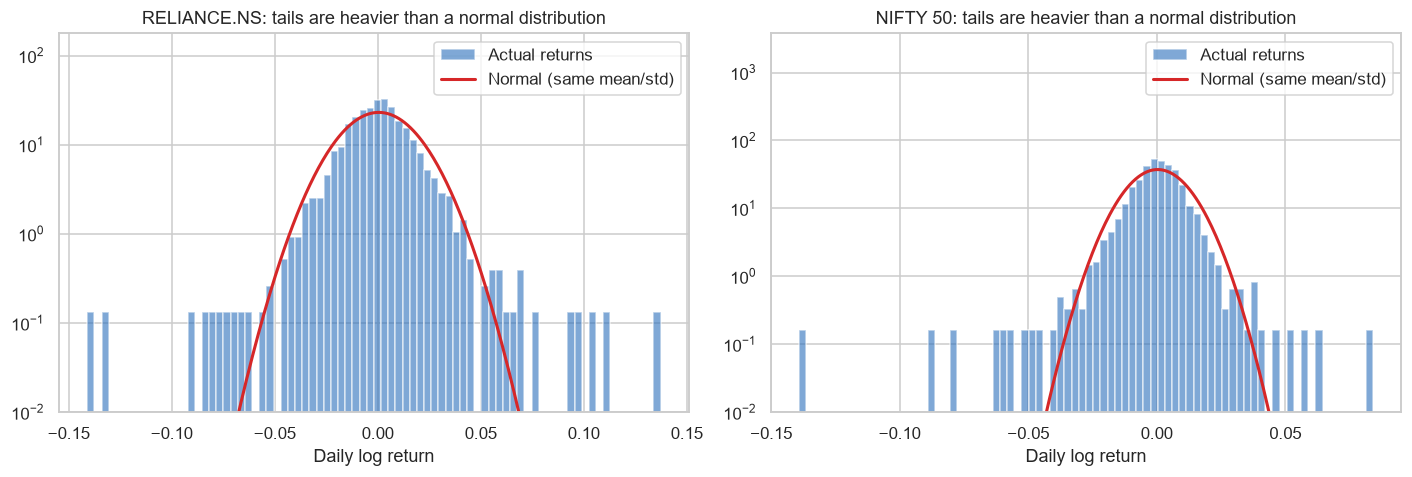

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, series) in zip(axes, [("RELIANCE.NS", returns["RELIANCE.NS"]),
                                      ("NIFTY 50", bench_ret.iloc[:, 0])]):
    mu, sigma = series.mean(), series.std()
    x = np.linspace(series.min(), series.max(), 400)
    ax.hist(series, bins=80, density=True, alpha=0.6, color="#2a6fbb", label="Actual returns")
    ax.plot(x, stats.norm.pdf(x, mu, sigma), color="#d62728", lw=2, label="Normal (same mean/std)")
    ax.set_yscale("log")
    ax.set_ylim(bottom=1e-2)
    ax.set_title(f"{name}: tails are heavier than a normal distribution")
    ax.set_xlabel("Daily log return"); ax.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "01_fat_tails_histogram.png", dpi=200, bbox_inches="tight")
plt.show()

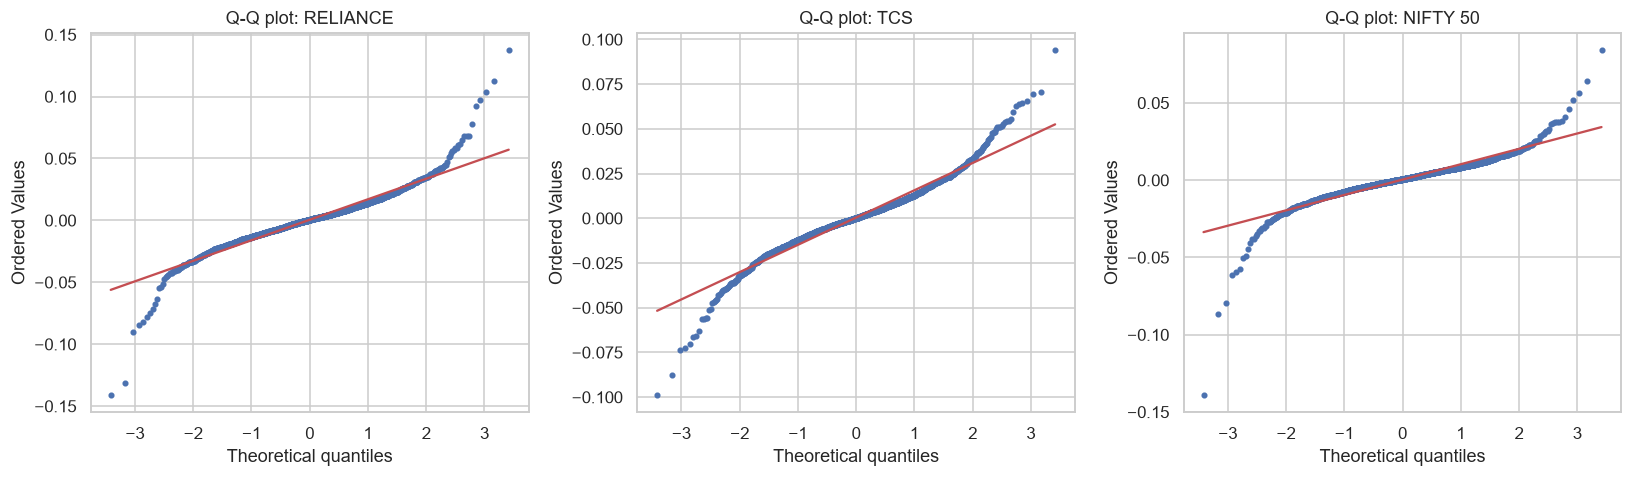

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, s) in zip(axes, [("RELIANCE", returns["RELIANCE.NS"]),
                                 ("TCS", returns["TCS.NS"]),
                                 ("NIFTY 50", bench_ret.iloc[:, 0])]):
    stats.probplot(s, dist="norm", plot=ax)
    ax.get_lines()[0].set_markersize(3)
    ax.set_title(f"Q-Q plot: {name}")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "02_qq_plots.png", dpi=200, bbox_inches="tight")
plt.show()

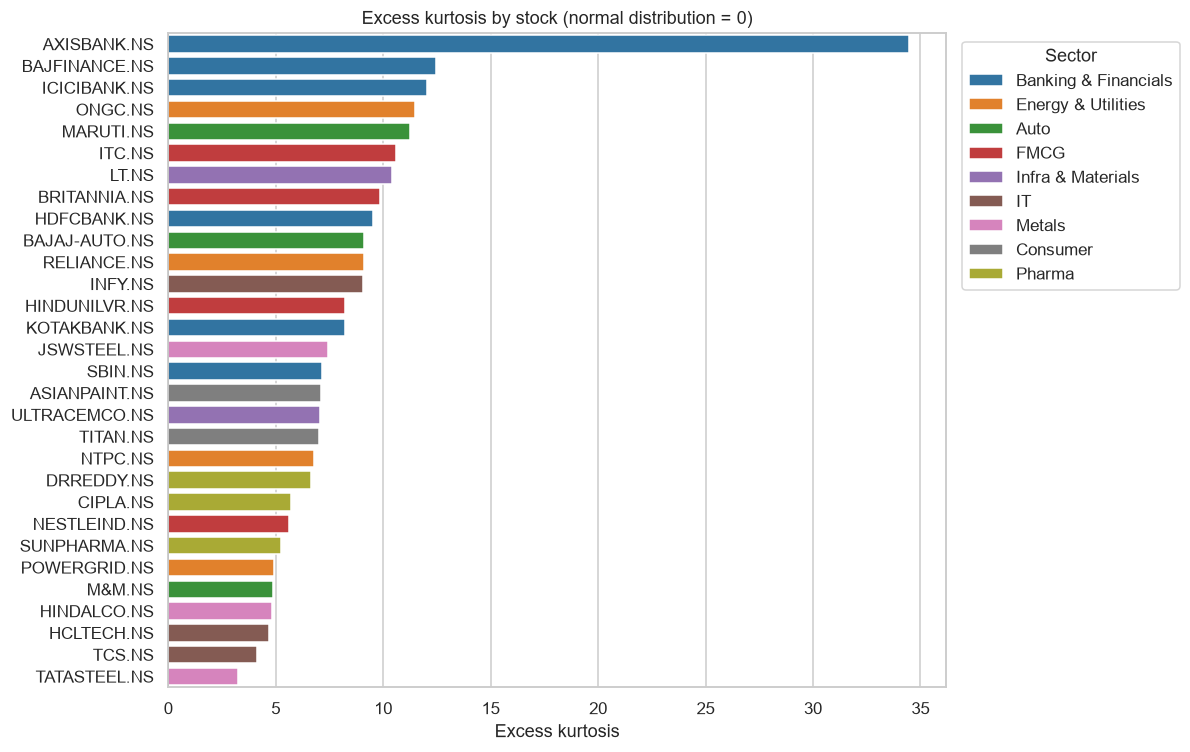

In [18]:
order = summary.sort_values("excess_kurtosis", ascending=False)
plt.figure(figsize=(11, 7))
sns.barplot(data=order.reset_index(names="ticker"), y="ticker", x="excess_kurtosis",
            hue="sector", dodge=False, palette="tab10")
plt.axvline(0, color="black", lw=1)
plt.title("Excess kurtosis by stock (normal distribution = 0)")
plt.xlabel("Excess kurtosis"); plt.ylabel("")
plt.legend(title="Sector", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "03_kurtosis_by_stock.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
print("Rejecting normality:", summary["reject_normality"].sum(), "of", len(summary))
print("Min kurtosis:", summary["excess_kurtosis"].min().round(2))
print("Max kurtosis:", summary["excess_kurtosis"].idxmax(), summary["excess_kurtosis"].max().round(2))
print("Highest-kurtosis sector (avg):", summary.groupby("sector")["excess_kurtosis"].mean().idxmax())
print("NIFTY 50 kurtosis:", round(bench_ret.iloc[:, 0].kurt(), 2))

Rejecting normality: 30 of 30
Min kurtosis: 3.23
Max kurtosis: AXISBANK.NS 34.47
Highest-kurtosis sector (avg): Banking & Financials
NIFTY 50 kurtosis: 21.47


## Conclusion

Daily returns of NSE large-caps are **not normally distributed**. The Jarque-Bera test rejects normality for **all 30 of 30** stocks, and NIFTY 50 (excess kurtosis **21.47**) shows the same behavior. Every stock has positive excess kurtosis (minimum **3.23**, maximum **34.47** for **AXISBANK**), and Q-Q plots show the deviation is concentrated in the tails while the center fits reasonably well. **Banking & Financials** has the heaviest tails on average.

**Implication:** standard deviation alone understates the probability of extreme losses, so the next notebook adds drawdown, VaR, and CVaR alongside volatility.